# Resume RAG & Job Matching: Experiments and Analysis

This notebook walks through the pipeline (`resume_rag.py` → FAISS → `job_matcher.py`) and measures:

1. **Dataset**: 50 resumes in 10 occupational categories, plus 8 job descriptions
2. **Chunking & metadata**: section detection and extracted fields
3. **Matching output**: the required JSON format and must-have filtering
4. **Retrieval accuracy**: P@5, P@10, R@10, MRR, nDCG@10 against graded ground truth
5. **Ablations**: retrieval mode (semantic / keyword / hybrid), chunking strategy, embedding model, score weights
6. **Latency**: index build, query embedding, FAISS search, end-to-end, plus FAISS scaling

In [1]:
import os, sys, json, time, warnings
warnings.filterwarnings("ignore")
# run from the project root so relative data paths (resumes/, job_descriptions/, index/) resolve
os.chdir(os.path.abspath(".." if os.path.basename(os.getcwd()) == "src" else "."))
sys.path.insert(0, os.getcwd())
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter
from src.file_tools import list_files, read_file
from src.resume_rag import ResumeRAG, split_sections, chunk_resume, extract_metadata
from src.job_matcher import JobMatcher, parse_job_description
from src.evaluation import evaluate, measure_latency, summarize_latency, load_ground_truth
from src.constants import METRICS, DEFAULT_MODEL, ALT_MODEL, INDEX_DIR, RESUMES_DIR
pd.set_option("display.max_colwidth", 80)

## 1. Dataset
Resumes come from the public Kaggle *Resume Dataset* (CC0), via its HuggingFace mirror `opensporks/resumes`, downloaded by `scripts/fetch_resumes.py`. The originals are anonymized, so every resume got a deterministic **synthetic** name. The category labels in `resumes/_labels.json` are used **only for evaluation**.

In [2]:
labels = json.load(open("resumes/_labels.json"))
files = list_files("resumes")
texts = {f.stem: read_file(f) for f in files}
ds = pd.DataFrame([{"resume": f.stem, "category": labels[f.name]["category"], "chars": len(texts[f.stem]),
                    "headline": texts[f.stem].split("\n")[0][:50]} for f in files])
print(f"{len(ds)} resumes, {ds.category.nunique()} categories, median length {int(ds.chars.median())} chars")
ds.groupby("category").agg(n=("resume", "count"), median_chars=("chars", "median"))

50 resumes, 10 categories, median length 5429 chars


,n,median_chars
category,,
ACCOUNTANT,5,5251.0
BANKING,5,6287.0
DESIGNER,5,6578.0
ENGINEERING,5,5628.0
FINANCE,5,5428.0
HEALTHCARE,5,4882.0
HR,5,5421.0
INFORMATION-TECHNOLOGY,5,5997.0
SALES,5,5148.0


In [3]:
jds = sorted(p for p in os.listdir("job_descriptions") if p.endswith(".txt"))
gt = load_ground_truth()
pd.DataFrame([{"jd": j, "title": read_file(f"job_descriptions/{j}").split("\n")[0],
               "relevant (2)": sum(v == 2 for v in gt[j].values()),
               "partial (1)": sum(v == 1 for v in gt[j].values())} for j in jds])

,jd,title,relevant (2),partial (1)
0,finance_manager.txt,Finance Manager (FP&A),5,5
1,graphic_designer.txt,Graphic Designer,3,2
2,hr_generalist.txt,HR Generalist / HR Manager,5,0
3,it_systems_admin.txt,IT Systems Administrator,5,1
4,quality_engineer.txt,Manufacturing / Quality Engineer,5,0
5,sales_associate.txt,Sales Representative,5,2
6,staff_accountant.txt,Staff Accountant,5,6
7,teacher.txt,Elementary School Teacher,5,0


## 2. Section-aware chunking & metadata extraction
Headers such as *Summary, Skills, Work History, Education and Training* are mapped onto canonical sections. Each section becomes one chunk, and sections longer than 1200 chars are split on line boundaries with 150 chars of overlap.

In [4]:
t0 = time.perf_counter()
rag = ResumeRAG(index_dir="index")
build_stats = rag.build("resumes"); rag.save()
build_stats

W1018 10:45:28.727000 12724 .venv/lib/python3.12/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

{'resumes': 50,
 'chunks': 456,
 'dim': 384,
 'parse_s': 7.42,
 'embed_s': 17.45,
 'total_s': 24.87}

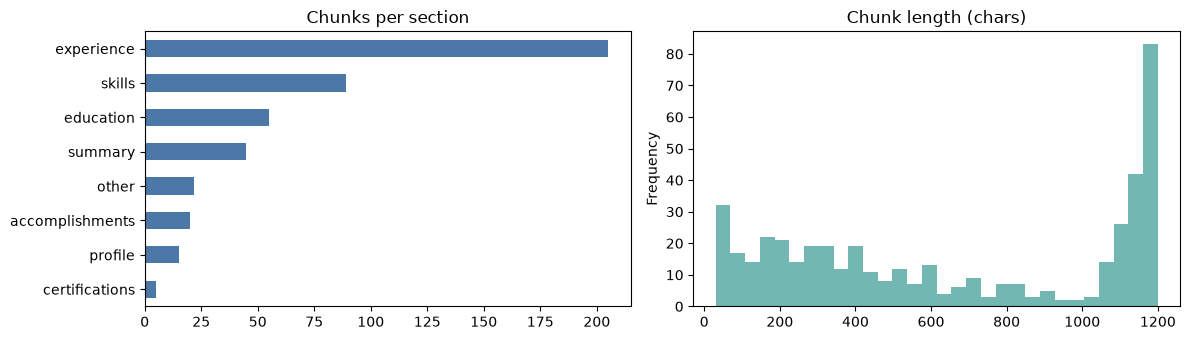

456 chunks; 100% of resumes have >= 4 detected sections; 45/50 with a degree found


In [5]:
sec_counts = Counter(c["section"] for c in rag.chunks)
detected = pd.Series({rid: len(m["sections"]) for rid, m in rag.resumes.items()})
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
pd.Series(sec_counts).sort_values().plot.barh(ax=ax[0], color="#4C78A8", title="Chunks per section")
pd.Series([len(c["text"]) for c in rag.chunks]).plot.hist(bins=30, ax=ax[1], color="#72B7B2", title="Chunk length (chars)")
plt.tight_layout(); plt.show()
print(f"{len(rag.chunks)} chunks; {(detected >= 4).mean():.0%} of resumes have >= 4 detected sections; "
      f"{sum(m['education']['degree'] is not None for m in rag.resumes.values())}/50 with a degree found")

In [6]:
meta = pd.DataFrame([{"name": m["name"], "category": labels[m["resume_id"] + ".pdf"]["category"],
                      "exp_years": m["experience_years"], "degree": m["education"]["degree"],
                      "field": m["education"]["field"], "n_skills": len(m["skills"]),
                      "top_skills": ", ".join(m["skills_primary"][:5] or m["skills"][:5])}
                     for m in rag.resumes.values()])
meta.sample(10, random_state=1)

,name,category,exp_years,degree,field,n_skills,top_skills
27,Lina Saleh,ENGINEERING,10.6,Bachelor,Electrical Engineering,10,"SQL, C++, HTML/CSS, Microsoft Office, Excel"
35,Noah Wilson,ENGINEERING,14.3,Master,Mechanical Engineering,12,"Data Analysis, Microsoft Office, Manufacturing, Project Management, Budgeting"
40,Ravi Iyer,HR,10.2,NaN,NaN,17,"Excel, Payroll, Sales, Customer Service, Retail"
38,Pavel Volkov,DESIGNER,9.3,NaN,NaN,9,"Excel, Fashion Design"
2,Amara Okafor,HR,5.2,Bachelor,Business Finance,16,"Microsoft Office, Excel, Accounting, Accounts Payable, Payroll"
3,Ana Pereira,HEALTHCARE,8.1,Bachelor,Human Resources Management,6,"Budgeting, Training & Development, Leadership, Communication, CPR/BLS"
48,Yuki Tanaka,BANKING,5.9,Bachelor,Health Administration Information Systems,10,"Microsoft Office, Banking, Sales, Customer Service, Performance Management"
29,Marco Bianchi,SALES,5.6,Diploma/Certificate,NaN,6,"Sales, Customer Service, Communication"
46,Tariq Aziz,DESIGNER,17.7,Bachelor,NaN,13,"Microsoft Office, AutoCAD, Project Management, Budgeting, Adobe Photoshop"
31,Mateo Lopez,TEACHER,2.9,Bachelor,Healthcare Administration,11,"Excel, Sales, Customer Service, Retail, Inventory Management"


## 3. Matching: the required output format
The hybrid score is `0.55·semantic + 0.25·skill coverage + 0.10·BM25 + 0.10·qualification fit`, scaled to 0–100. Must-haves are auto-detected from `Must have:` lines in the JD, or passed with `--must` on `python main.py match`.

In [7]:
matcher = JobMatcher(rag)
jd_text = read_file("job_descriptions/staff_accountant.txt")
res = matcher.match(jd_text, k=10)
print(json.dumps(res["parsed_requirements"], indent=1))
pd.DataFrame([{k: m[k] for k in ["candidate_name", "match_score", "matched_sections", "experience_years"]}
              | {"category": labels[os.path.basename(m["resume_path"])]["category"]} for m in res["top_matches"]])

{
 "required_skills": [
  "Financial Reporting",
  "General Ledger",
  "Reconciliation",
  "Accounts Payable",
  "Accounts Receivable",
  "Auditing",
  "Tax",
  "Accounting",
  "Excel"
 ],
 "preferred_skills": [
  "CPA",
  "SAP",
  "Oracle",
  "QuickBooks"
 ],
 "must_haves": [
  "3+ years Accounting"
 ],
 "min_years": 3.0,
 "degree_level": 3
}


,candidate_name,match_score,matched_sections,experience_years,category
0,Omar Haddad,83,[experience],8.1,FINANCE
1,Andre Moore,78,"[skills, experience]",31.5,ACCOUNTANT
2,Ethan Clark,69,"[experience, summary]",8.1,ACCOUNTANT
3,Samuel Turner,66,"[skills, experience]",9.1,FINANCE
4,James Smith,66,"[experience, summary, skills]",7.6,FINANCE
5,Sara Cohen,65,"[experience, skills]",11.8,FINANCE
6,Elena Popescu,65,"[experience, summary]",8.0,ACCOUNTANT
7,Felix Weber,63,"[experience, skills]",9.9,FINANCE
8,Amara Okafor,61,"[accomplishments, experience, summary]",5.2,HR
9,Mia Young,51,"[experience, summary]",12.0,ACCOUNTANT


In [8]:
m = res["top_matches"][0]
print(json.dumps({"job_description": jd_text[:120] + "...", "top_matches": [
    {k: m[k] for k in ["candidate_name", "resume_path", "match_score", "matched_skills", "relevant_excerpts", "reasoning"]}]}, indent=2))

{
  "job_description": "Staff Accountant\n\nOur finance team needs a detail-oriented Staff Accountant to support month-end close and financial rep...",
  "top_matches": [
    {
      "candidate_name": "Omar Haddad",
      "resume_path": "resumes/omar_haddad.pdf",
      "match_score": 83,
      "matched_skills": [
        "Financial Reporting",
        "General Ledger",
        "Reconciliation",
        "Accounts Payable",
        "Accounts Receivable",
        "Auditing",
        "Accounting",
        "Excel",
        "SAP"
      ],
      "relevant_excerpts": [
        "[Experience] Supervise the media finance, production, client finance, accounts payable and accounts receivable departments.",
        "[Experience] Ensure that all monthly balance sheet reconciliations are completed and any reconciling items are addressed and resolved.",
        "[Experience] Prepared and reconciled accrual and deferral schedules on a monthly basis."
      ],
      "reasoning": "Strong semantic match fo

**Must-have filtering.** The IT JD already auto-detects two must-haves (3+ years experience, Networking). Stacking CLI must-haves on top of them (`Linux`, `Python:5`) shrinks the pool to zero, and every rejected candidate gets a concrete reason.

In [9]:
it = read_file("job_descriptions/it_systems_admin.txt")
for extra in ([], ["Linux"], ["Python:5"]):
    r = matcher.match(it, k=10, must=extra)
    print(f"must={r['parsed_requirements']['must_haves']}\n  -> {r['stats']['passed_filters']} pass: "
          f"{[x['candidate_name'] for x in r['top_matches']]}")
    if r["filtered_out"]: print("  e.g. filtered:", r["filtered_out"][0])

must=['3+ years experience', 'Networking']
  -> 7 pass: ['Hannah Fischer', 'Zara Ali', 'Chen Wang', 'Fatima Rahman', 'Amara Okafor', 'Kwame Mensah', 'Sofia Rossi']
  e.g. filtered: {'candidate_name': 'Leila Nasser', 'reasons': ['1.8 yrs experience < 3 required']}
must=['3+ years experience', 'Networking', 'Linux']
  -> 0 pass: []
  e.g. filtered: {'candidate_name': 'Hannah Fischer', 'reasons': ['missing must-have skill Linux']}
must=['3+ years experience', 'Networking', '5+ years Python']
  -> 0 pass: []
  e.g. filtered: {'candidate_name': 'Hannah Fischer', 'reasons': ['missing must-have skill Python']}


## 4. Retrieval accuracy
Ground truth is graded: **2** means the same occupational category, **1** means an adjacent role chosen by hand. P/R/MRR count grade ≥ 1 as relevant, and nDCG uses the grades. Must-have filters are **off** here so that we measure ranking quality. Filtering is a separate business rule.

In [10]:
ev = evaluate(matcher)
summary = ev.groupby("mode")[METRICS].mean().loc[["semantic", "keyword", "hybrid"]]
summary.round(3)

,P@5,P@10,R@10,MRR,nDCG@10
mode,,,,,
semantic,0.850,0.588,0.904,1.0,0.881
keyword,0.800,0.550,0.823,1.0,0.858
hybrid,0.875,0.600,0.915,1.0,0.906


In [11]:
ev[ev["mode"] == "hybrid"].set_index("jd")[METRICS].round(2)

,P@5,P@10,R@10,MRR,nDCG@10
jd,,,,,
it_systems_admin,1.0,0.6,1.00,1.0,0.98
staff_accountant,1.0,1.0,0.91,1.0,0.77
hr_generalist,0.8,0.5,1.00,1.0,0.99
finance_manager,1.0,0.7,0.70,1.0,0.91
sales_associate,0.8,0.5,0.71,1.0,0.65
graphic_designer,0.8,0.5,1.00,1.0,0.99
teacher,1.0,0.5,1.00,1.0,1.00
quality_engineer,0.6,0.5,1.00,1.0,0.96


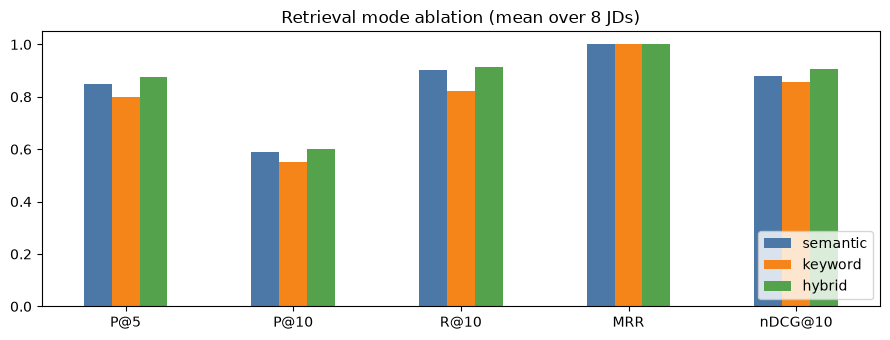

In [12]:
ax = summary.T.plot.bar(figsize=(9, 3.5), rot=0, color=["#4C78A8", "#F58518", "#54A24B"], title="Retrieval mode ablation (mean over 8 JDs)")
ax.set_ylim(0, 1.05); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

Note: **P@10 is capped** by the number of relevant resumes per JD (5–11), so ~0.6 can be near-perfect. R@10 and nDCG@10 are the more informative numbers.

## 5. Ablations
### 5a. Chunking strategy and embedding model

In [13]:
configs = {
    "bge-small + section chunks": (DEFAULT_MODEL, "section", "index"),
    "bge-small + fixed 800-char": (DEFAULT_MODEL, "fixed", "index_fixed"),
    "MiniLM-L6 + section chunks": (ALT_MODEL, "section", "index_minilm"),
}
rows, matchers = [], {}
for label, (model, chunker, idx) in configs.items():
    r = rag if idx == "index" else ResumeRAG(model, idx, chunker)
    if idx != "index":
        st = r.build("resumes"); r.save()
    else:
        st = build_stats
    mt = JobMatcher(r); matchers[label] = mt
    e = evaluate(mt, modes=("semantic", "hybrid")).groupby("mode")[METRICS].mean()
    for mode, vals in e.iterrows():
        rows.append({"config": label, "mode": mode, "chunks": st["chunks"], "build_s": st["total_s"], **vals.round(3)})
abl = pd.DataFrame(rows).set_index(["config", "mode"])
abl

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

chunks  build_s    P@5   P@10   R@10  \
config                     mode                                             
bge-small + section chunks hybrid       456    24.87  0.875  0.600  0.915   
                           semantic     456    24.87  0.850  0.588  0.904   
bge-small + fixed 800-char hybrid       433    14.53  0.850  0.612  0.928   
                           semantic     433    14.53  0.825  0.588  0.904   
MiniLM-L6 + section chunks hybrid       456    13.49  0.875  0.575  0.853   
                           semantic     456    13.49  0.800  0.512  0.739   

                                     MRR  nDCG@10  
config                     mode                    
bge-small + section chunks hybrid    1.0    0.906  
                           semantic  1.0    0.881  
bge-small + fixed 800-char hybrid    1.0    0.908  
                           semantic  1.0    0.902  
MiniLM-L6 + section chunks hybrid    1.0    0.885  
                           semantic  1.0    0.809

### 5b. Weight sensitivity (hybrid)
The semantic weight is varied and the remainder is shared out in the default proportions.

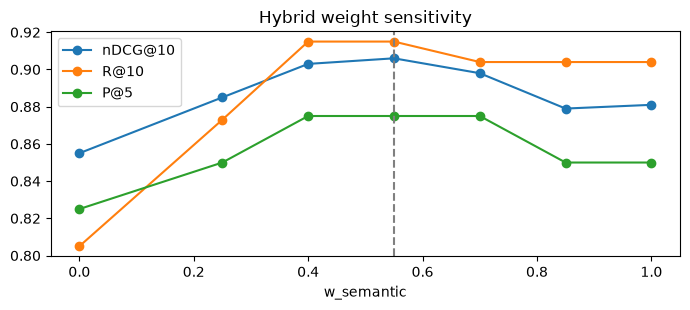

,P@5,P@10,R@10,MRR,nDCG@10
w_semantic,,,,,
0.00,0.825,0.538,0.805,1.0,0.855
0.25,0.850,0.575,0.873,1.0,0.885
0.40,0.875,0.600,0.915,1.0,0.903
0.55,0.875,0.600,0.915,1.0,0.906
0.70,0.875,0.588,0.904,1.0,0.898
0.85,0.850,0.588,0.904,1.0,0.879
1.00,0.850,0.588,0.904,1.0,0.881


In [14]:
sens = []
for w_sem in [0.0, 0.25, 0.4, 0.55, 0.7, 0.85, 1.0]:
    rest = 1 - w_sem
    mt = JobMatcher(rag, weights={"semantic": w_sem, "skills": rest * 0.25 / 0.45,
                                  "keyword": rest * 0.10 / 0.45, "qualification": rest * 0.10 / 0.45})
    e = evaluate(mt, modes=("hybrid",))[METRICS].mean()
    sens.append({"w_semantic": w_sem, **e.round(3)})
sens = pd.DataFrame(sens).set_index("w_semantic")
ax = sens[["nDCG@10", "R@10", "P@5"]].plot(marker="o", figsize=(7, 3.2), title="Hybrid weight sensitivity")
ax.axvline(0.55, ls="--", c="grey"); plt.tight_layout(); plt.show(); sens

## 6. Latency

In [15]:
lat = measure_latency(matcher, runs=50)
lat_sum = summarize_latency(lat)
print("Index build:", build_stats)
lat_sum

Index build: {'resumes': 50, 'chunks': 456, 'dim': 384, 'parse_s': 7.42, 'embed_s': 17.45, 'total_s': 24.87}


,p50_ms,p95_ms,mean_ms
embed_query,19.00,21.71,18.64
faiss_search,0.04,0.05,0.04
total,50.70,63.70,47.72
wall,50.74,63.74,47.76


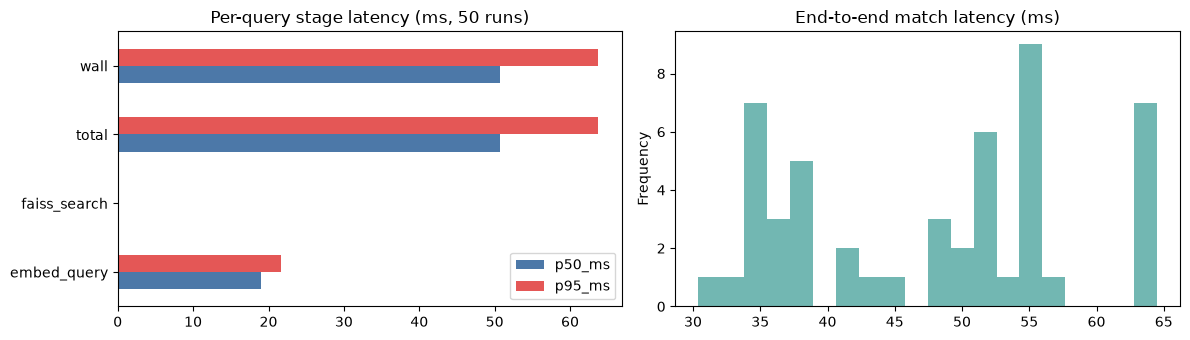

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
lat_sum[["p50_ms", "p95_ms"]].plot.barh(ax=ax[0], title="Per-query stage latency (ms, 50 runs)", color=["#4C78A8", "#E45756"])
lat["total"].plot.hist(bins=20, ax=ax[1], color="#72B7B2", title="End-to-end match latency (ms)")
plt.tight_layout(); plt.show()

### FAISS scaling
Our index has only ~450 vectors, so search costs microseconds. The cell below times `IndexFlatIP` (exact) against `IndexHNSWFlat` (approximate) on random 384-d vectors, to show what happens as the resume pool grows.

In [17]:
import faiss
rng = np.random.default_rng(0)
scal = []
for n in [1_000, 10_000, 100_000]:
    xb = rng.standard_normal((n, 384)).astype("float32"); faiss.normalize_L2(xb)
    xq = rng.standard_normal((100, 384)).astype("float32"); faiss.normalize_L2(xq)
    for name, idx in [("FlatIP (exact)", faiss.IndexFlatIP(384)), ("HNSW32 (approx)", faiss.IndexHNSWFlat(384, 32, faiss.METRIC_INNER_PRODUCT))]:
        t = time.perf_counter(); idx.add(xb); add_s = time.perf_counter() - t
        t = time.perf_counter(); idx.search(xq, 100); q_ms = (time.perf_counter() - t) * 1000 / 100
        scal.append({"vectors": n, "index": name, "add_s": round(add_s, 2), "search_ms/query": round(q_ms, 3)})
pd.DataFrame(scal).pivot(index="vectors", columns="index", values="search_ms/query")

index,FlatIP (exact),HNSW32 (approx)
vectors,,
1000,0.015,0.015
10000,0.157,0.018
100000,2.119,0.075


## 7. All JDs: top-3 per job (hybrid, with must-have filters)

In [18]:
out = []
for j in jds:
    r = matcher.match(read_file(f"job_descriptions/{j}"), k=3)
    for rank, m in enumerate(r["top_matches"], 1):
        out.append({"jd": j[:-4], "rank": rank, "candidate": m["candidate_name"], "score": m["match_score"],
                    "category": labels[os.path.basename(m["resume_path"])]["category"],
                    "relevance": gt[j].get(os.path.basename(m["resume_path"])[:-4], 0)})
pd.DataFrame(out).set_index(["jd", "rank"])

candidate  score                category  \
jd               rank                                                  
finance_manager  1        Felix Weber     86                 FINANCE   
                 2        Omar Haddad     82                 FINANCE   
                 3      Samuel Turner     77                 FINANCE   
graphic_designer 1          Grace Kim     86                DESIGNER   
                 2         Jonah Reed     85                DESIGNER   
                 3        Hugo Martin     84                DESIGNER   
hr_generalist    1        Priya Patel    100                      HR   
                 2       Isabel Costa     81                      HR   
                 3          Ravi Iyer     68                      HR   
it_systems_admin 1     Hannah Fischer     67  INFORMATION-TECHNOLOGY   
                 2           Zara Ali     49  INFORMATION-TECHNOLOGY   
                 3          Chen Wang     47  INFORMATION-TECHNOLOGY   
quality_engineer 1         Kenji Sato     73             ENGINEERING   
                 2        Noah Wilson     72             ENGINEERING   
                 3         Emma Brown     71             ENGINEERING   
sales_associate  1         Leo Moreau     73                   SALES   
                 2       Amara Okafor     71                      HR   
                 3      Fatima Rahman     67                 BANKING   
staff_accountant 1        Omar Haddad     83                 FINANCE   
                 2        Andre Moore     78              ACCOUNTANT   
                 3        Ethan Clark     69              ACCOUNTANT   
teacher          1        Lucas Silva     81                 TEACHER   
                 2      Daniel Miller     78                 TEACHER   
                 3       Victor Novak     59                 TEACHER   

                       relevance  
jd               rank             
finance_manager  1             2  
                 2             2  
                 3             2  
graphic_designer 1             2  
                 2             2  
                 3             2  
hr_generalist    1             2  
                 2             2  
                 3             2  
it_systems_admin 1             2  
                 2             2  
                 3             2  
quality_engineer 1             2  
                 2             2  
                 3             2  
sales_associate  1             2  
                 2             0  
                 3             1  
staff_accountant 1             1  
                 2             2  
                 3             2  
teacher          1             2  
                 2             2  
                 3             2

In [19]:
print(json.dumps({"hybrid_mean": summary.loc["hybrid"].round(3).to_dict(),
                  "semantic_mean": summary.loc["semantic"].round(3).to_dict(),
                  "keyword_mean": summary.loc["keyword"].round(3).to_dict(),
                  "latency_p50_ms": lat_sum["p50_ms"].to_dict()}, indent=1))

{
 "hybrid_mean": {
  "P@5": 0.875,
  "P@10": 0.6,
  "R@10": 0.915,
  "MRR": 1.0,
  "nDCG@10": 0.906
 },
 "semantic_mean": {
  "P@5": 0.85,
  "P@10": 0.588,
  "R@10": 0.904,
  "MRR": 1.0,
  "nDCG@10": 0.881
 },
 "keyword_mean": {
  "P@5": 0.8,
  "P@10": 0.55,
  "R@10": 0.823,
  "MRR": 1.0,
  "nDCG@10": 0.858
 },
 "latency_p50_ms": {
  "embed_query": 19.0,
  "faiss_search": 0.04,
  "total": 50.7,
  "wall": 50.74
 }
}


## 8. Findings & limitations
**Retrieval mode.** Hybrid gives the best result: mean nDCG@10 is **0.906**, against 0.881 for semantic-only and 0.858 for keyword-only. R@10 is 0.915. In the weight sweep, quality plateaus for semantic weights between 0.40 and 0.55, and drops at either extreme (pure keyword 0.855, pure semantic 0.881). Embeddings capture the role. Skill and BM25 signals sharpen the ranking within a role.

**Embedding model.** bge-small is clearly better than MiniLM-L6 in semantic-only mode (nDCG 0.881 vs 0.821, R@10 0.904 vs 0.757). Hybrid scoring closes most of that gap (0.885), because the keyword and skill signals make up for weaker embeddings.

**Chunking: a mixed result.** Fixed 800-character windows rank about as well as section-aware chunks (hybrid nDCG 0.908 vs 0.906, semantic-only 0.902 vs 0.881). These resumes are short (about 5k chars), so a whole section carries little more signal than a window. What section-aware chunking buys is **explainability**: `matched_sections`, section-labelled excerpts, and skills taken from the Skills section first. The ranking itself does not improve.

**Hardest queries.** Sales (nDCG 0.65) is the hardest: its vocabulary (customer service, retail, inventory) appears in many categories, so HR, banking and teacher resumes compete. Staff Accountant (0.77) is next, because senior Finance resumes (graded as partial matches) outrank some accountants.

**Must-have filters are brittle.** They depend on literal keywords. None of the 5 accountant resumes contains the word "Excel", so a hard `Excel` requirement would reject every accountant. That is why each JD keeps only 1–3 must-haves, and why accuracy is measured with filters off.

**Latency (CPU, Apple Silicon).** The end-to-end match takes about **54 ms at p50** (70 ms at p95). Query embedding takes about 21 ms, FAISS search about 0.05 ms, and BM25, scoring and excerpt selection take the rest. Building the index for 50 resumes takes about 24 s, most of it embedding. Exact `IndexFlatIP` still costs only about 2.6 ms per query at 100k vectors, and HNSW drops that to about 0.09 ms. FAISS will not be the bottleneck at realistic resume-pool sizes.

**Limitations.** Metadata extraction is regex-based. Experience comes from merged date ranges, with "Current" resolved to the latest year in the resume. Names are synthetic. Relevance is judged by category, which is coarse. With only 8 queries, differences of about 0.02 are not statistically meaningful.